In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
MESSAGE_FILE = "MSFT_2012-06-21_34200000_57600000_message_10.csv"
ORDERBOOK_FILE = "MSFT_2012-06-21_34200000_57600000_orderbook_10.csv"

In [5]:
message = pd.read_csv(MESSAGE_FILE, header=None, names=['Time', 'Type', 'Order ID', 'Size', 'Price', 'Direction'])
message.head()

,Time,Type,Order ID,Size,Price,Direction
0,34200.013994,3,16085616,100,310400,-1
1,34200.013994,1,16116348,100,310500,-1
2,34200.015248,1,16116658,100,310400,-1
3,34200.015442,1,16116704,100,310500,-1
4,34200.015789,1,16116752,100,310600,-1


In [7]:
market_orders = message[message['Type'].isin([4, 5])]['Size']
limit_orders = message[message['Type'] == 1]['Size']

In [9]:
def empirical_distribution(series):
    """
    Returns:
    x = unique order sizes
    y = probability of each size
    """
    counts = series.value_counts().sort_index()
    probs = counts / counts.sum()
    return counts.index.values, probs.values


market_x, market_y = empirical_distribution(market_orders)
limit_x, limit_y = empirical_distribution(limit_orders)

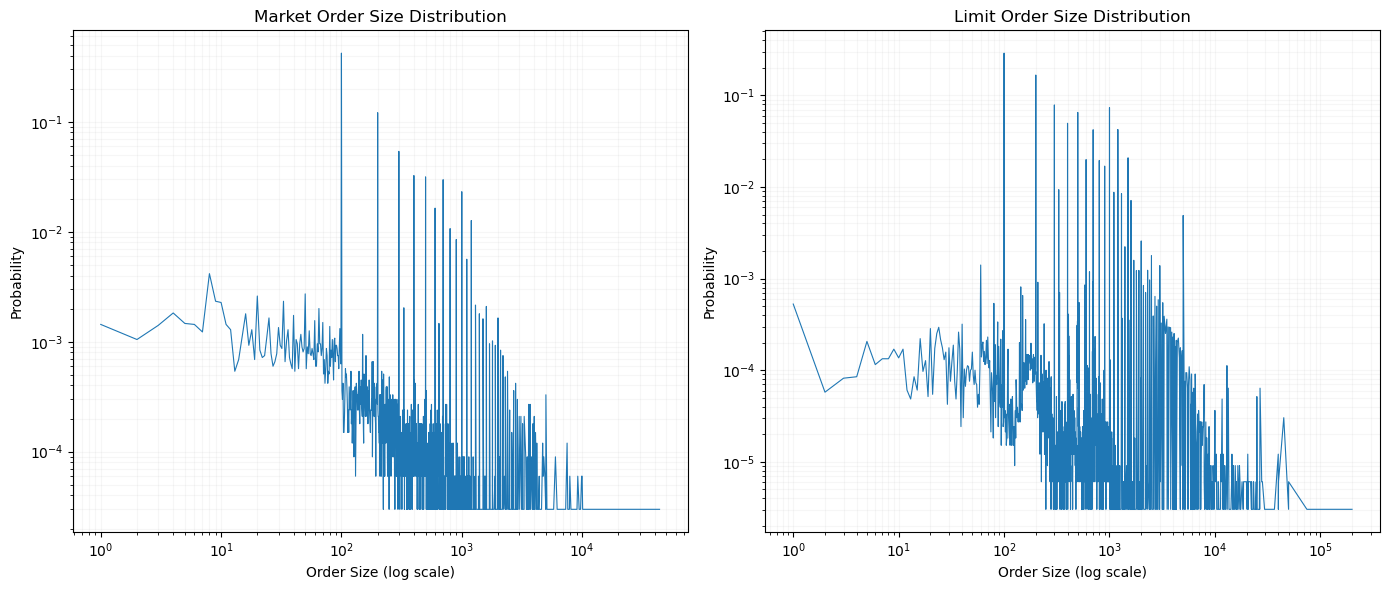

In [13]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(
    market_x,
    market_y,
    linewidth=0.8
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Order Size (log scale)")
plt.ylabel("Probability")
plt.title("Market Order Size Distribution")
plt.grid(True, which="both", alpha=0.1)

plt.subplot(1, 2, 2)
plt.plot(
    limit_x,
    limit_y,
    linewidth=0.8
)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Order Size (log scale)")
plt.ylabel("Probability")
plt.title("Limit Order Size Distribution")
plt.grid(True, which="both", alpha=0.1)
plt.tight_layout()
plt.savefig('Size Distribution')
plt.show()

In [17]:
limit_orders = message[message["Type"] == 1].copy()

In [19]:
BIN_SIZE = 600  # 10 minutes in seconds
market_open = 34200
limit_orders["Bin"] = (
    (limit_orders["Time"] - market_open) // BIN_SIZE
).astype(int)
limit_orders = limit_orders[
    (limit_orders["Bin"] >= 0) &
    (limit_orders["Bin"] <= 38)
]
bin_counts = (
    limit_orders
    .groupby("Bin")
    .size()
    .reindex(range(39), fill_value=0)
)
orders_per_sec = bin_counts / BIN_SIZE
rolling_std = orders_per_sec.rolling(
    window=3,
    center=True,
    min_periods=1
).std().fillna(0)

lower = np.maximum(
    orders_per_sec - rolling_std,
    0
)

upper = orders_per_sec + rolling_std

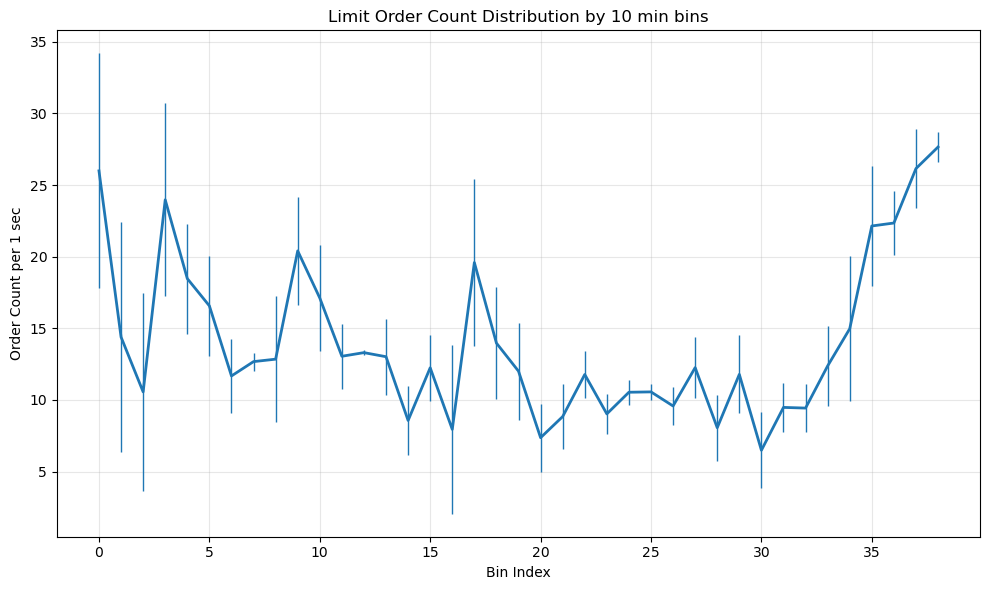

In [21]:
plt.figure(figsize=(10, 6))
plt.vlines(
    x=orders_per_sec.index,
    ymin=lower,
    ymax=upper,
    linewidth=1
)

plt.plot(
    orders_per_sec.index,
    orders_per_sec.values,
    linewidth=2
)

plt.title("Limit Order Count Distribution by 10 min bins")
plt.xlabel("Bin Index")
plt.ylabel("Order Count per 1 sec")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('U Curve')
plt.show()

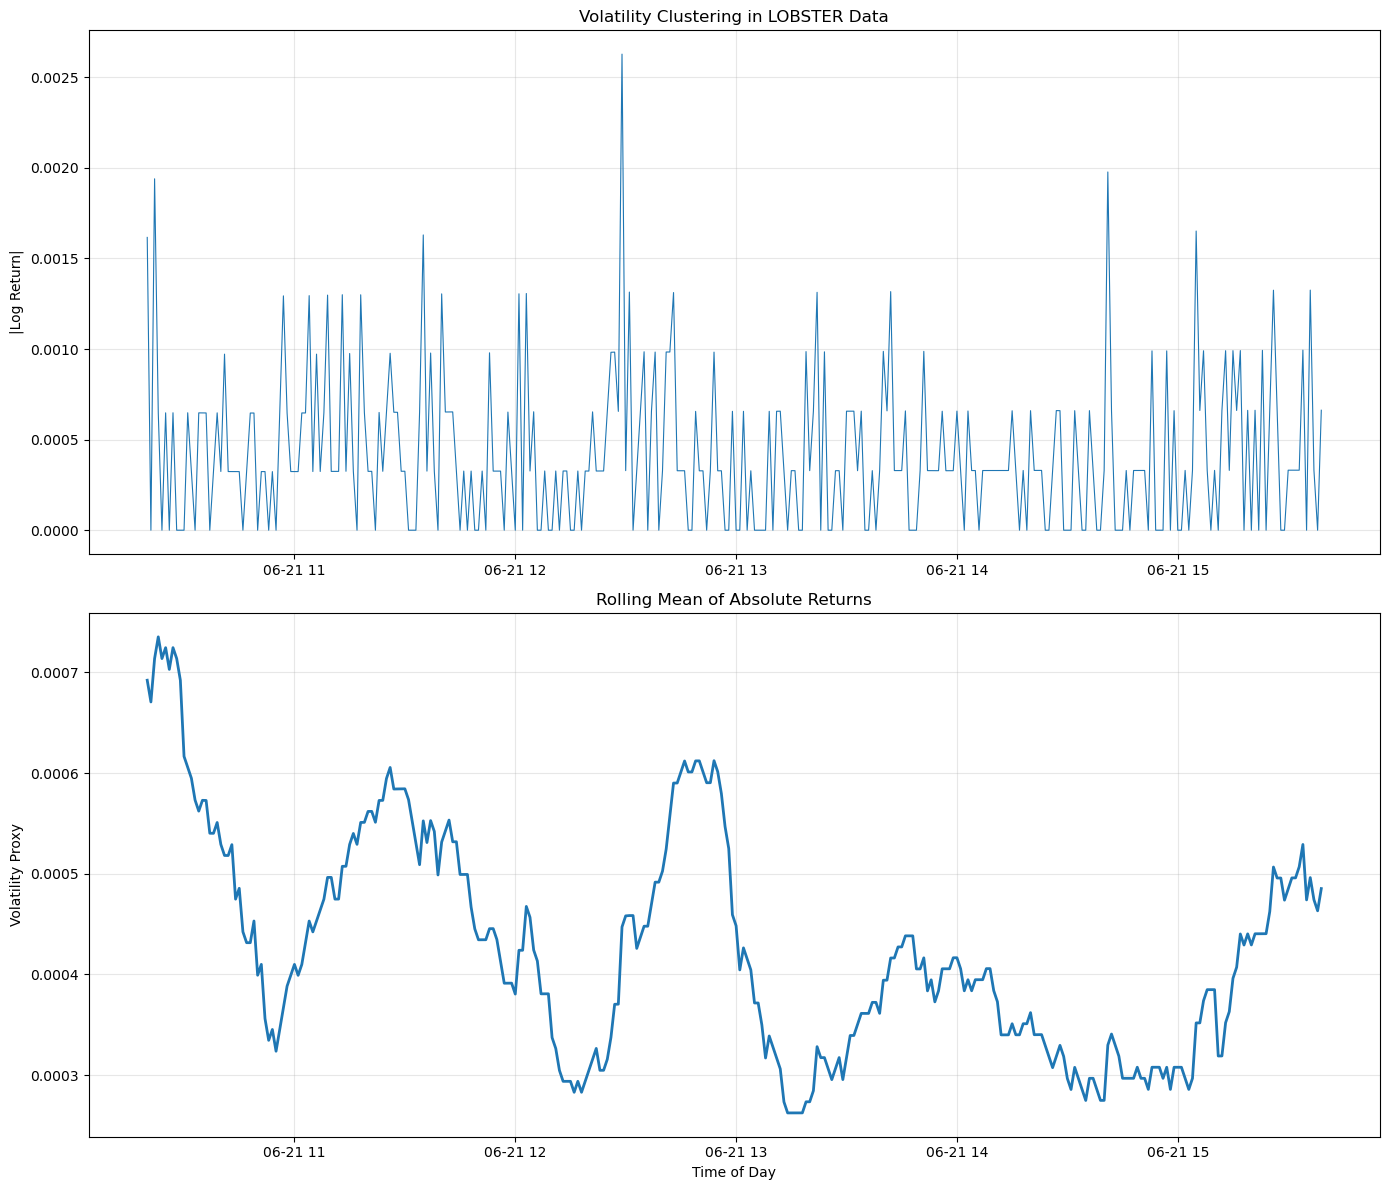

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Load LOBSTER files
# --------------------------------------------------

MESSAGE_FILE = "MSFT_2012-06-21_34200000_57600000_message_10.csv"
ORDERBOOK_FILE = "MSFT_2012-06-21_34200000_57600000_orderbook_10.csv"

# message file (for timestamps)
message = pd.read_csv(
    MESSAGE_FILE,
    header=None,
    names=["Time", "Type", "Order ID", "Size", "Price", "Direction"]
)

# orderbook file (for bid/ask prices)
orderbook = pd.read_csv(
    ORDERBOOK_FILE,
    header=None
)

# --------------------------------------------------
# Keep only top of book columns
# --------------------------------------------------

orderbook = orderbook.rename(columns={
    0: "Ask Price 1",
    2: "Bid Price 1"
})

# attach timestamps from message file
orderbook["Time"] = message["Time"]

# --------------------------------------------------
# Midprice
# --------------------------------------------------

orderbook["Midprice"] = (
    orderbook["Ask Price 1"] +
    orderbook["Bid Price 1"]
) / 2

# LOBSTER scaling correction
orderbook["Midprice"] = orderbook["Midprice"] / 10000

# --------------------------------------------------
# Resample to fixed clock-time intervals
#
# This is MUCH better than event-time
# for showing volatility clustering
#
# Here: 1-minute intervals
# --------------------------------------------------

# convert seconds after midnight to pandas datetime
base_date = "2012-06-21"

orderbook["Datetime"] = pd.to_datetime(base_date) + pd.to_timedelta(
    orderbook["Time"],
    unit="s"
)

orderbook = orderbook.set_index("Datetime")

# use last midprice every 1 minute
midprice_1min = orderbook["Midprice"].resample("1min").last()

# forward fill missing values if needed
midprice_1min = midprice_1min.ffill()

# --------------------------------------------------
# Compute log returns
# --------------------------------------------------

log_returns = np.log(midprice_1min).diff()

# absolute returns are visually stronger
abs_returns = np.abs(log_returns)

# rolling realized volatility
WINDOW = 30   # 30-minute smoothing window

rolling_vol = (
    log_returns
    .rolling(WINDOW)
    .std()
)

# rolling mean of absolute returns
rolling_abs = (
    abs_returns
    .rolling(WINDOW)
    .mean()
)

# --------------------------------------------------
# Remove opening and closing spikes
# Optional but improves visualization
# --------------------------------------------------

plot_data = pd.DataFrame({
    "Abs Return": abs_returns,
    "Rolling Vol": rolling_vol,
    "Rolling Abs": rolling_abs
}).dropna()

plot_data = plot_data.iloc[20:-20]

# --------------------------------------------------
# Final Plot (Best visual for clustering)
# --------------------------------------------------

plt.figure(figsize=(14, 12))

# -------------------------------
# Top panel: absolute returns
# -------------------------------

plt.subplot(2, 1, 1)

plt.plot(
    plot_data.index,
    plot_data["Abs Return"],
    linewidth=0.8
)

plt.title("Volatility Clustering in LOBSTER Data")
plt.ylabel("|Log Return|")
plt.grid(True, alpha=0.3)

# -------------------------------
# Bottom panel:
# smoothed volatility
# -------------------------------

plt.subplot(2, 1, 2)

plt.plot(
    plot_data.index,
    plot_data["Rolling Abs"],
    linewidth=2
)

plt.title("Rolling Mean of Absolute Returns")
plt.ylabel("Volatility Proxy")
plt.xlabel("Time of Day")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Volatility Clustering')
plt.show()

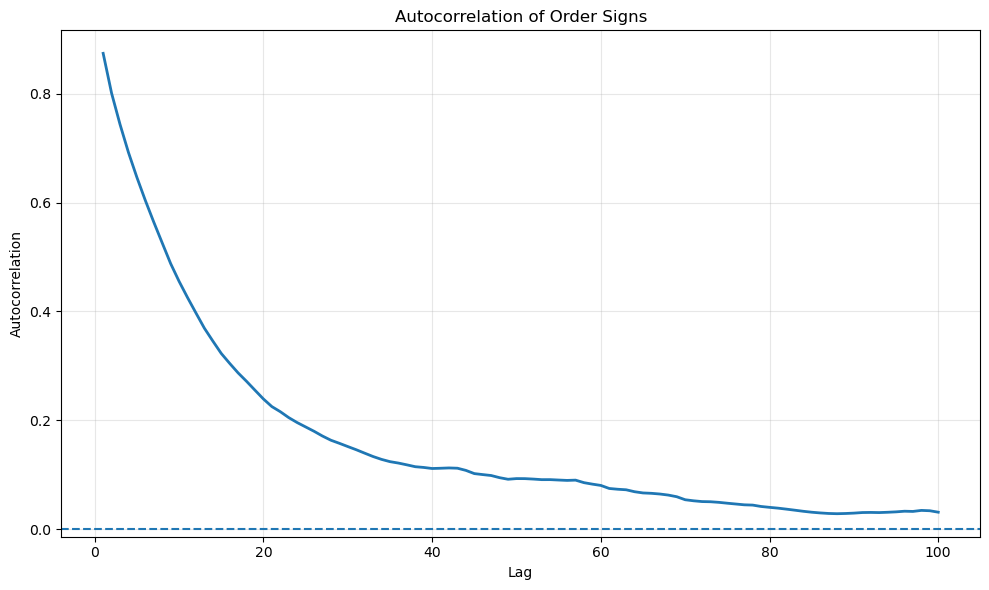

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# Load LOBSTER message file
# -----------------------------------

MESSAGE_FILE = "MSFT_2012-06-21_34200000_57600000_message_10.csv"

message = pd.read_csv(
    MESSAGE_FILE,
    header=None,
    names=[
        "Time",
        "Type",
        "Order ID",
        "Size",
        "Price",
        "Direction"
    ]
)

# -----------------------------------
# Keep only market orders
#
# Type 4 = execution of visible order
# Type 5 = execution of hidden order
# -----------------------------------

market_orders = message[
    message["Type"].isin([4, 5])
].copy()

# -----------------------------------
# Order sign series
#
# Direction:
# +1 = Buy
# -1 = Sell
# -----------------------------------

order_sign = market_orders["Direction"].values

# -----------------------------------
# Compute autocorrelation manually
# -----------------------------------

MAX_LAG = 100

autocorr = []

for lag in range(1, MAX_LAG + 1):
    corr = np.mean(
        order_sign[:-lag] *
        order_sign[lag:]
    )
    autocorr.append(corr)

# -----------------------------------
# Plot
# -----------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, MAX_LAG + 1),
    autocorr,
    linewidth=2
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Autocorrelation of Order Signs")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Autocorrelation')
plt.show()
